# v4 comparison: why BUS misses subtle time-series patterns, and what fixes it
Reads `results_v4/` from `walmart_v4`, `favorita_v4`, `favorita_monthly_v4`, `m5_v4`, `m5_weekly_v4`.

In [1]:
import itertools
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)


def load(kind):
    files = sorted(glob.glob(f"results_v4/*_{kind}.csv"))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True)


tasks, seeds, meta = load("tasks"), load("seeds"), load("meta")
tasks["found"] = tasks["rank"] <= 20
METHODS = list(dict.fromkeys(tasks["method"]))
DATASETS = list(meta["dataset"])
display(meta.round(4))

,dataset,N,T,period,n_descriptors,n_conditions,store_level_share,n_stores,noise_rel_std,autocorr_lag1,seasonality_r2,intermittency,sigma_rate,sigma_season,sigma_vol
0,favorita,1100,910,day,8,67,0.7500,53,0.3726,0.2202,0.0000,0.0489,0.1173,0.0337,0.2162
1,favorita_monthly,1100,30,month,8,67,0.7500,53,0.1079,0.3269,0.0050,0.0366,0.1173,0.0325,0.4896
2,m5,6581,1238,day,9,41,0.1111,10,0.8922,0.1464,0.0000,0.3129,0.0396,0.0092,0.0541
3,m5_weekly,6581,176,week,9,41,0.1111,10,0.4456,0.3710,0.0002,0.1079,0.0398,0.0095,0.0810
4,walmart,2566,143,week,15,62,1.0000,45,0.1360,0.4413,0.0189,0.0000,0.0468,0.0133,0.1225


## Q4a. Seed diagnostics: what are the mini-clusters made of, and do they ever contain the planted group?

In [2]:
display(seeds.pivot_table(index="seed", columns="dataset", values=["purity", "planted_coverage", "candidate_recall"],
                          sort=False).round(2))
display(seeds.groupby("seed", sort=False)[["distinct_records", "size_percentile", "mean_size", "candidates",
                                           "seed_time_s", "purity_if_random"]].mean().round(3))
print("candidate recall per pattern")
display(seeds.pivot_table(index="pattern", columns="seed", values="candidate_recall", sort=False).round(2))

candidate recall per pattern


purity                                  planted_coverage                                  candidate_recall                                 
dataset        favorita_monthly favorita    m5 m5_weekly walmart favorita_monthly favorita    m5 m5_weekly walmart favorita_monthly favorita    m5 m5_weekly walmart
seed                                                                                                                                                                
closest-$                  0.02     0.04  0.08      0.06    0.05             0.03     0.02  0.00      0.00    0.01             0.24     0.23  0.25      0.19    0.26
alpha-$                    0.02     0.04  0.08      0.06    0.05             0.03     0.02  0.00      0.00    0.01             0.24     0.23  0.25      0.19    0.27
closest-rel                0.01     0.01  0.04      0.03    0.03             0.03     0.05  0.01      0.01    0.04             0.37     0.47  0.18      0.24    0.69
closest-blocks             0.01     0.01  0.04      0.03    0.02             0.03     0.04  0.02      0.01    0.04             0.35     0.40  0.45      0.33    0.69
snn-pairs                  0.09     0.10  0.09      0.08    0.12             0.20     0.23  0.04      0.03    0.12             0.68     0.76  0.67      0.69    0.82
snn-components             0.03     0.04  0.03      0.02    0.04             0.42     0.48  0.06      0.06    0.24             0.73     0.74  0.64      0.63    0.88

,distinct_records,size_percentile,mean_size,candidates,seed_time_s,purity_if_random
seed,,,,,,
closest-$,46.328,0.030,2.000,949.381,2.971,0.049
alpha-$,47.306,0.030,2.000,957.030,3.855,0.049
closest-rel,119.252,0.893,2.000,2397.485,3.046,0.049
closest-blocks,154.528,0.818,2.000,2438.446,1.594,0.049
snn-pairs,177.859,0.612,2.000,2405.246,0.948,0.049
snn-components,430.306,0.625,7.461,2393.907,1.237,0.049


seed,closest-$,alpha-$,closest-rel,closest-blocks,snn-pairs,snn-components
pattern,,,,,,
level,0.39,0.40,0.60,0.74,0.91,0.87
trend,0.37,0.37,0.52,0.53,0.88,0.83
stockout,0.12,0.11,0.06,0.19,0.47,0.56
season,0.33,0.33,0.58,0.58,0.79,0.79
lag,0.12,0.13,0.32,0.39,0.71,0.74
volatility,0.08,0.08,0.26,0.24,0.59,0.56


## Q4b + Q1. End to end: share of planted subgroups in the top-20, per dataset and per pattern

In [3]:
display(tasks.pivot_table(index="dataset", columns="method", values="found", sort=False)[METHODS].round(2))
display(tasks.pivot_table(index=["pattern", "snr"], columns="method", values="found", sort=False)[METHODS].round(2))
display(tasks.groupby("method", sort=False)[["found", "evaluated_hit", "evaluated", "runtime_s", "seed_time_s"]].mean().round(3))

method,BS w=10,BS,BUS closest-$,BUS→BS pool α-$,BUS closest-rel,BUS closest-blocks,BUS snn-pairs,BUS snn-components,BUS→BS pool blocks,BUS→BS pool snn,BUS snn-pairs +local,BUS closest-blocks +local
dataset,,,,,,,,,,,,
favorita_monthly,0.55,0.57,0.18,0.42,0.28,0.28,0.46,0.49,0.44,0.53,0.56,0.51
favorita,0.55,0.59,0.19,0.44,0.30,0.27,0.51,0.50,0.42,0.52,0.52,0.51
m5,0.33,0.34,0.09,0.21,0.06,0.14,0.29,0.31,0.30,0.32,0.33,0.31
m5_weekly,0.38,0.37,0.07,0.19,0.10,0.11,0.31,0.27,0.30,0.36,0.37,0.32
walmart,0.46,0.43,0.12,0.25,0.25,0.24,0.31,0.35,0.29,0.33,0.40,0.38


method          BS w=10    BS  BUS closest-$  BUS→BS pool α-$  BUS closest-rel  BUS closest-blocks  BUS snn-pairs  BUS snn-components  BUS→BS pool blocks  BUS→BS pool snn  BUS snn-pairs +local  BUS closest-blocks +local
pattern    snr                                                                                                                                                                                                             
level      2       0.33  0.33           0.30             0.30             0.37                0.30           0.33                0.33                0.33             0.33                  0.33                       0.30
           4       0.67  0.63           0.23             0.40             0.50                0.60           0.63                0.60                0.60             0.67                  0.63                       0.63
           8       0.93  0.93           0.43             0.73             0.60                0.70           0.93                0.90                0.73             0.93                  0.93                       0.93
trend      2       0.40  0.37           0.17             0.30             0.27                0.27           0.33                0.33                0.30             0.37                  0.33                       0.27
           4       0.70  0.77           0.23             0.50             0.37                0.37           0.67                0.70                0.63             0.70                  0.70                       0.63
           8       0.97  0.97           0.33             0.57             0.60                0.53           0.93                0.97                0.87             0.97                  0.97                       0.93
stockout   2       0.27  0.27           0.00             0.17             0.00                0.00           0.10                0.13                0.17             0.20                  0.23                       0.27
           4       0.63  0.63           0.00             0.37             0.03                0.03           0.30                0.47                0.33             0.47                  0.57                       0.60
           8       0.93  1.00           0.23             0.57             0.03                0.27           0.70                0.77                0.57             0.77                  1.00                       0.90
season     2       0.03  0.03           0.03             0.03             0.00                0.00           0.00                0.00                0.03             0.03                  0.03                       0.00
           4       0.03  0.00           0.03             0.03             0.00                0.00           0.07                0.03                0.03             0.03                  0.03                       0.00
           8       0.10  0.13           0.13             0.17             0.17                0.17           0.30                0.27                0.20             0.23                  0.27                       0.17
lag        2       0.00  0.00           0.00             0.00             0.00                0.00           0.00                0.00                0.00             0.00                  0.00                       0.00
           4       0.00  0.00           0.00             0.00             0.00                0.00           0.00                0.00                0.00             0.00                  0.00                       0.00
           8       0.00  0.00           0.00             0.00             0.00                0.00           0.00                0.00                0.00             0.00                  0.00                       0.00
volatility 2       0.37  0.37           0.03             0.37             0.30                0.17           0.23                0.30                0.30             0.43                  0.27                       0.27
           4       0.83  0.87           

,found,evaluated_hit,evaluated,runtime_s,seed_time_s
method,,,,,
BS w=10,0.454,0.570,279.315,1.366,0.000
BS,0.461,0.831,635.735,3.219,0.000
BUS closest-$,0.130,0.235,389.502,4.886,2.971
BUS→BS pool α-$,0.304,0.500,497.848,6.298,3.855
BUS closest-rel,0.196,0.385,526.663,5.368,3.046
BUS closest-blocks,0.207,0.443,590.444,4.259,1.594
BUS snn-pairs,0.374,0.717,627.243,3.741,0.948
BUS snn-components,0.383,0.719,654.633,4.256,1.237
BUS→BS pool blocks,0.346,0.572,533.402,4.238,1.594


## Equal budget: share in the top-20 within B evaluations / t seconds (all datasets and patterns)

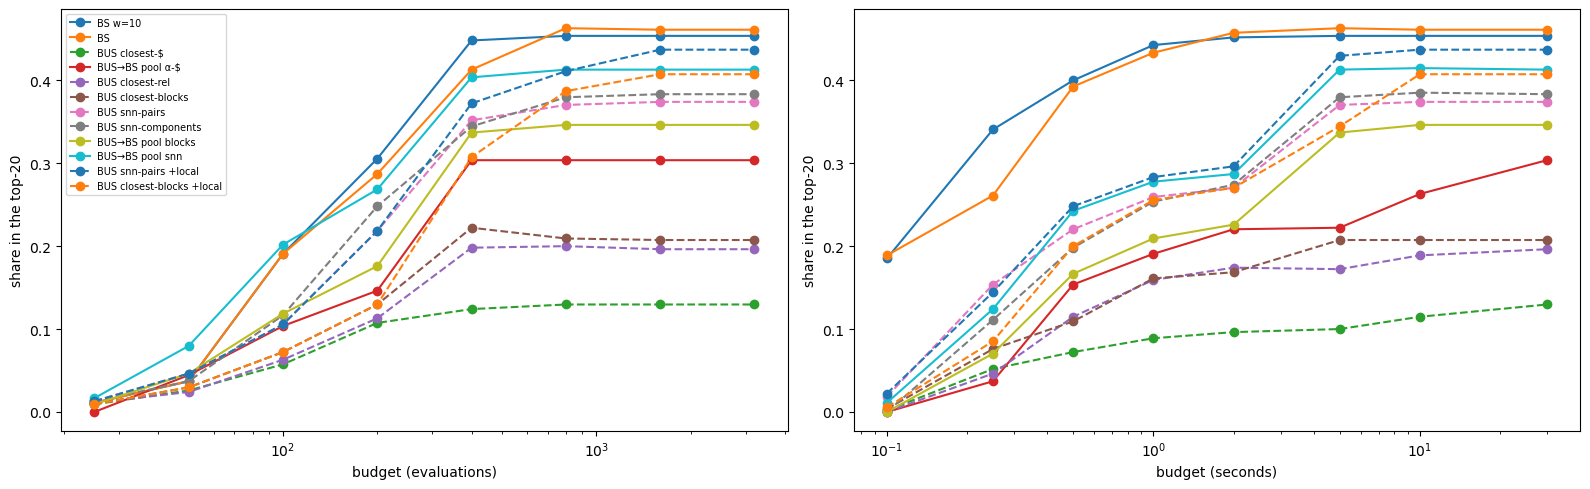

,@100,@400,@1600,@0.5s,@2s,@10s
BS w=10,0.19,0.45,0.45,0.40,0.45,0.45
BS,0.19,0.41,0.46,0.39,0.46,0.46
BUS closest-$,0.06,0.12,0.13,0.07,0.10,0.11
BUS→BS pool α-$,0.10,0.30,0.30,0.15,0.22,0.26
BUS closest-rel,0.06,0.20,0.20,0.11,0.17,0.19
BUS closest-blocks,0.07,0.22,0.21,0.11,0.17,0.21
BUS snn-pairs,0.11,0.35,0.37,0.22,0.27,0.37
BUS snn-components,0.12,0.34,0.38,0.20,0.27,0.39
BUS→BS pool blocks,0.12,0.34,0.35,0.17,0.23,0.35
BUS→BS pool snn,0.20,0.40,0.41,0.24,0.29,0.41


In [4]:
BUDGETS = [25, 50, 100, 200, 400, 800, 1600, 3200]
SECONDS = [0.1, 0.25, 0.5, 1, 2, 5, 10, 30]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (grid, suffix, label) in zip(axes, [(BUDGETS, "", "evaluations"), (SECONDS, "s", "seconds")]):
    for method in METHODS:
        g = tasks[tasks["method"] == method]
        ax.plot(grid, [np.mean(g[f"rank_at_{b}{suffix}"] <= 20) for b in grid], marker="o", label=method,
                ls="-" if method.startswith(("BS", "BUS→")) else "--")
    ax.set_xscale("log")
    ax.set_xlabel(f"budget ({label})")
    ax.set_ylabel("share in the top-20")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
display(pd.DataFrame({m: {**{f"@{b}": np.mean(tasks.loc[tasks.method == m, f"rank_at_{b}"] <= 20) for b in [100, 400, 1600]},
                          **{f"@{s}s": np.mean(tasks.loc[tasks.method == m, f"rank_at_{s}s"] <= 20) for s in [0.5, 2, 10]}}
                      for m in METHODS}).T.round(2))

## Q3. Does local search from BUS candidates help?

In [5]:
pairs = [("BUS snn-pairs", "BUS snn-pairs +local"), ("BUS closest-blocks", "BUS closest-blocks +local")]
rows = []
for base, local in pairs:
    a = tasks[tasks.method == base].set_index(["dataset", "pattern", "snr", "lits", "rep"])
    b = tasks[tasks.method == local].set_index(["dataset", "pattern", "snr", "lits", "rep"])
    rows.append({"base": base, "found_base": a["found"].mean(), "found_local": b["found"].mean(),
                 "rescued": (b["found"] & ~a["found"]).mean(), "lost": (~b["found"] & a["found"]).mean(),
                 "extra_evaluations": (b["evaluated"] - a["evaluated"]).mean(), "extra_seconds": (b["runtime_s"] - a["runtime_s"]).mean()})
display(pd.DataFrame(rows).round(3))

,base,found_base,found_local,rescued,lost,extra_evaluations,extra_seconds
0,BUS snn-pairs,0.374,0.437,0.067,0.004,41.052,0.372
1,BUS closest-blocks,0.207,0.407,0.202,0.002,47.380,0.371


## Q2. Meta-learning: in which contexts does a BUS variant beat beam search with a narrow beam?
Target per task: found(best BUS variant) − found(BS w=10), and per BUS variant separately. Contexts are found with
subgroup discovery itself (exhaustive, depth ≤ 2, numeric WRAcc = coverage × (mean in context − overall mean)),
as in Bart's meta-analysis (Tables 6.5 / 6.7).

In [6]:
key = ["dataset", "pattern", "snr", "lits", "rep"]
wide = tasks.pivot_table(index=key, columns="method", values="found").reset_index()
bus_methods = [m for m in METHODS if m.startswith("BUS") and "pool α-$" not in m and m != "BUS closest-$"]
wide["best_bus"] = wide[bus_methods].max(axis=1)
wide["target"] = wide["best_bus"].astype(float) - wide["BS w=10"].astype(float)
task_meta = tasks.drop_duplicates(key)[key + ["coverage", "planted_size_pct", "store_conds", "item_conds", "record_conds", "measure"]]
mt = wide.merge(task_meta, on=key).merge(meta, on="dataset")

features = {"pattern": mt["pattern"], "measure": mt["measure"], "snr": mt["snr"].astype(str), "lits": mt["lits"].astype(str),
            "period": mt["period"], "T": pd.qcut(mt["T"], 3, duplicates="drop").astype(str),
            "N": pd.qcut(mt["N"], 3, duplicates="drop").astype(str),
            "n_conditions": pd.qcut(mt["n_conditions"], 3, duplicates="drop").astype(str),
            "noise": pd.qcut(mt["noise_rel_std"], 3, duplicates="drop").astype(str),
            "autocorr": pd.qcut(mt["autocorr_lag1"], 3, duplicates="drop").astype(str),
            "intermittency": pd.qcut(mt["intermittency"], 3, duplicates="drop").astype(str),
            "coverage": pd.qcut(mt["coverage"], 3, duplicates="drop").astype(str),
            "planted_size": pd.qcut(mt["planted_size_pct"], 3, duplicates="drop").astype(str),
            "record_level_conds": (mt["record_conds"] + mt["item_conds"] > 0).map({True: "yes", False: "no"})}
F = pd.DataFrame(features)
y = mt["target"].to_numpy()
conds = [(c, v) for c in F.columns for v in F[c].unique()]
results = []
for depth in (1, 2):
    for combo in itertools.combinations(conds, depth):
        if len({c for c, _ in combo}) < depth:
            continue
        m = np.ones(len(F), dtype=bool)
        for c, v in combo:
            m &= (F[c] == v).to_numpy()
        if m.sum() < 10:
            continue
        results.append({"context": " AND ".join(f"{c} = {v}" for c, v in combo), "n": int(m.sum()),
                        "mean(BUS - BS w=10)": y[m].mean(), "wracc": m.mean() * (y[m].mean() - y.mean())})
res = pd.DataFrame(results)
print(f"overall mean(best BUS - BS w=10) = {y.mean():.3f} over {len(y)} tasks")
print("contexts where BUS gains most")
display(res.sort_values("wracc", ascending=False).head(12).round(3))
print("contexts where BUS loses most")
display(res.sort_values("wracc").head(12).round(3))

overall mean(best BUS - BS w=10) = 0.041 over 540 tasks
contexts where BUS gains most
contexts where BUS loses most


,context,n,mean(BUS - BS w=10),wracc
427,"lits = 3 AND N = (1099.999, 6581.0]",270,0.089,0.024
428,"lits = 3 AND n_conditions = (40.999, 67.0]",270,0.089,0.024
13,lits = 3,270,0.089,0.024
436,"lits = 3 AND intermittency = (-0.00099455, 0.0366]",108,0.139,0.020
425,"lits = 3 AND T = (29.999, 143.0]",108,0.139,0.020
430,"lits = 3 AND noise = (0.107, 0.136]",108,0.139,0.020
439,"lits = 3 AND coverage = (0.019, 0.0394]",103,0.126,0.016
445,lits = 3 AND record_level_conds = no,72,0.153,0.015
441,"lits = 3 AND planted_size = (0.484, 0.515]",87,0.126,0.014
422,lits = 3 AND period = month,54,0.167,0.013


,context,n,mean(BUS - BS w=10),wracc
403,"lits = 2 AND n_conditions = (40.999, 67.0]",270,-0.007,-0.024
402,"lits = 2 AND N = (1099.999, 6581.0]",270,-0.007,-0.024
12,lits = 2,270,-0.007,-0.024
342,snr = 4 AND lits = 2,90,-0.056,-0.016
419,lits = 2 AND record_level_conds = yes,176,-0.006,-0.015
418,"lits = 2 AND planted_size = (0.515, 0.618]",85,-0.047,-0.014
411,"lits = 2 AND intermittency = (-0.00099455, 0.0366]",108,-0.028,-0.014
405,"lits = 2 AND noise = (0.107, 0.136]",108,-0.028,-0.014
400,"lits = 2 AND T = (29.999, 143.0]",108,-0.028,-0.014
398,lits = 2 AND period = week,108,-0.028,-0.014
